========== UCB ==========
Video Lectures selected 257 times
Interactive Quizzes selected 68 times
Gamified Modules selected 675 times
Total Reward = 664

========== Thompson Sampling ==========
Video Lectures selected 279 times
Interactive Quizzes selected 15 times
Gamified Modules selected 706 times
Total Reward = 671


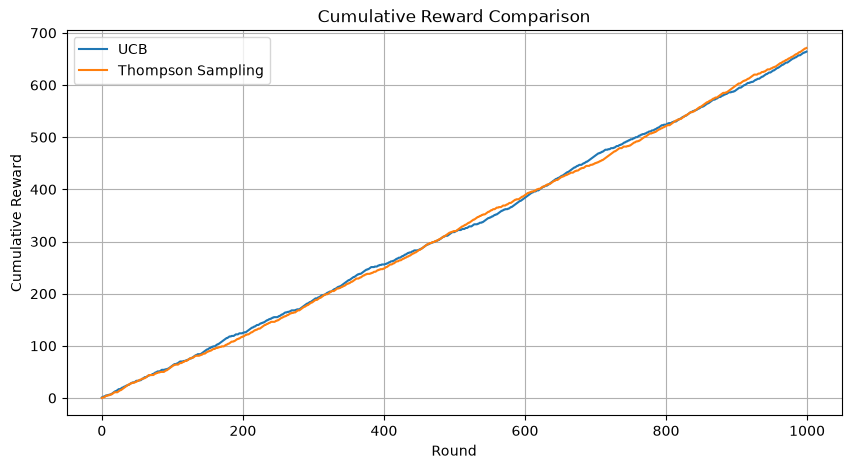

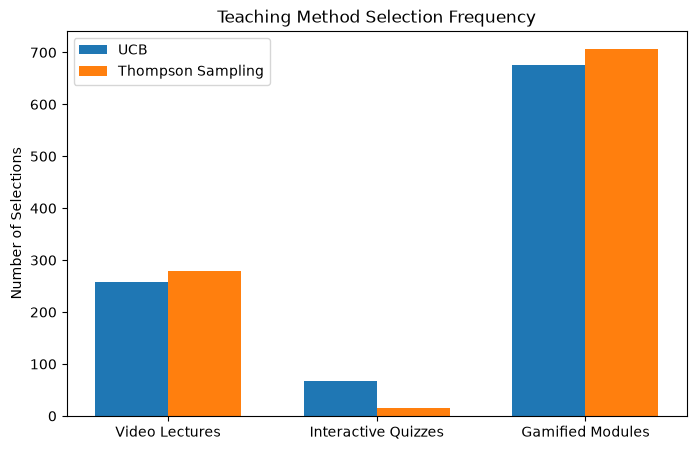

In [1]:
# Import NumPy for numerical computations
import numpy as np

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# ============================================================
# ENVIRONMENT
# ============================================================

# Set a random seed for reproducible results
np.random.seed(42)

# Define the names of the three teaching methods (arms)
arms = ["Video Lectures", "Interactive Quizzes", "Gamified Modules"]

# Define the true success probability of each arm
probabilities = [0.6, 0.4, 0.7]

# Get the total number of arms
n_arms = len(arms)

# Set the total number of rounds (student sessions)
rounds = 1000

# ============================================================
# UCB (Upper Confidence Bound)
# ============================================================

# Initialize the number of times each arm is selected
counts_ucb = np.zeros(n_arms)

# Initialize the estimated reward (Q-value) for each arm
values_ucb = np.zeros(n_arms)

# Store rewards obtained in each round
rewards_ucb = []

# Store cumulative rewards
cumulative_rewards_ucb = []

# Initialize total reward
total_reward = 0

# Run the UCB algorithm
for t in range(rounds):

    # Select each arm once during the initial rounds
    if t < n_arms:
        action = t
    else:

        # Compute the confidence value for each arm
        confidence = np.sqrt(
            (2 * np.log(t + 1)) / counts_ucb
        )

        # Compute the UCB value
        ucb = values_ucb + confidence

        # Select the arm with the highest UCB value
        action = np.argmax(ucb)

    # Generate a reward (1 = success, 0 = failure)
    reward = np.random.binomial(1, probabilities[action])

    # Increase the selection count of the chosen arm
    counts_ucb[action] += 1

    # Update the estimated reward using incremental averaging
    values_ucb[action] += (
        reward - values_ucb[action]
    ) / counts_ucb[action]

    # Update the total reward
    total_reward += reward

    # Store the reward
    rewards_ucb.append(reward)

    # Store the cumulative reward
    cumulative_rewards_ucb.append(total_reward)

# Display UCB results
print("========== UCB ==========")

# Print how many times each arm was selected
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ucb[i]), "times")

# Print the total reward
print("Total Reward =", total_reward)

# ============================================================
# THOMPSON SAMPLING
# ============================================================

# Initialize alpha values of the Beta distribution
alpha = np.ones(n_arms)

# Initialize beta values of the Beta distribution
beta = np.ones(n_arms)

# Initialize arm selection counts
counts_ts = np.zeros(n_arms)

# Store rewards obtained
rewards_ts = []

# Store cumulative rewards
cumulative_rewards_ts = []

# Reset total reward
total_reward = 0

# Run Thompson Sampling
for t in range(rounds):

    # Sample a probability from each Beta distribution
    samples = np.random.beta(alpha, beta)

    # Select the arm with the highest sampled value
    action = np.argmax(samples)

    # Generate reward from the selected arm
    reward = np.random.binomial(1, probabilities[action])

    # Increase the selection count
    counts_ts[action] += 1

    # Update Beta distribution parameters
    if reward == 1:

        # Increase alpha after a success
        alpha[action] += 1
    else:

        # Increase beta after a failure
        beta[action] += 1

    # Update the total reward
    total_reward += reward

    # Store the reward
    rewards_ts.append(reward)

    # Store cumulative reward
    cumulative_rewards_ts.append(total_reward)

# Display Thompson Sampling results
print("\n========== Thompson Sampling ==========")

# Print arm selection counts
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ts[i]), "times")

# Print total reward
print("Total Reward =", total_reward)

# ============================================================
# CUMULATIVE REWARD COMPARISON
# ============================================================

# Create a new figure
plt.figure(figsize=(10, 5))

# Plot cumulative reward of UCB
plt.plot(cumulative_rewards_ucb, label="UCB")

# Plot cumulative reward of Thompson Sampling
plt.plot(cumulative_rewards_ts, label="Thompson Sampling")

# Label the x-axis
plt.xlabel("Round")

# Label the y-axis
plt.ylabel("Cumulative Reward")

# Set graph title
plt.title("Cumulative Reward Comparison")

# Display the legend
plt.legend()

# Display grid lines
plt.grid()

# Show the graph
plt.show()

# ============================================================
# ARM SELECTION COMPARISON
# ============================================================

# Create x-axis positions for the bars
x = np.arange(n_arms)

# Set the width of each bar
width = 0.35

# Create a new figure
plt.figure(figsize=(8, 5))

# Plot UCB arm selection counts
plt.bar(
    x - width / 2,
    counts_ucb,
    width,
    label="UCB"
)

# Plot Thompson Sampling arm selection counts
plt.bar(
    x + width / 2,
    counts_ts,
    width,
    label="Thompson Sampling"
)

# Display arm names on the x-axis
plt.xticks(x, arms)

# Label the y-axis
plt.ylabel("Number of Selections")

# Set graph title
plt.title("Teaching Method Selection Frequency")

# Display the legend
plt.legend()

# Show the graph
plt.show()